# Clustering evaluation: ARI / NMI vs GICS sectors

The clustering notebook produced labels for several panel/K-scheme combinations. The question for this notebook: how well do those labels agree with the human-curated GICS sector labels?

I use two standard cluster-comparison metrics:

- **ARI** (Adjusted Rand Index): fraction of pairs (i, j) of stocks that get the "same/different cluster" treatment in both label sets, corrected for chance. Range 0 to 1, 1 = perfect agreement.
- **NMI** (Normalized Mutual Information): how much information the cluster labels share with the sector labels, normalized to 0 to 1.

Both are permutation-invariant, so it doesn't matter whether my "cluster 3" corresponds to GICS "Technology" or any other label.

What I expect, given the design of the residualization:

- Q0 (raw returns) clustering should be dominated by the market factor, so its agreement with GICS sectors should be weak.
- Q1 (CAPM residual) should have its strongest factor be Energy (as I saw in the preprocessing notebook). Clustering on Q1 should recover sectors reasonably well, so ARI should be at its highest here.
- Q2 (sector-beta residual) explicitly strips the sector signal, so clustering on Q2 should move AWAY from GICS. ARI should drop sharply. This is not a failure of Q2: it's evidence that Q2 is recovering sub-sector or idiosyncratic structure, not sector structure.

The clustering notebook produced labels for four methods (kmeans, Ward, average, single). I only score kmeans and Ward here because the diagnostic plot showed that average and single linkage chain into one giant cluster, which makes ARI/NMI uninformative.


## 1. Setup


In [9]:

import pandas as pd
import arcticdb as adb
import matplotlib.pyplot as plt
%matplotlib inline
from pathlib import Path
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ARCTIC_URI = "lmdb://./database/arctic"
ac = adb.Arctic(ARCTIC_URI)
clusters_lib = ac["clusters_lib"]
stocks_lib   = ac["stocks_lib"]
removed_lib  = ac["removed_stocks"]

OUTPUTS = Path("outputs"); OUTPUTS.mkdir(exist_ok=True)
METHODS = ["kmeans", "ward"]


20260522 13:12:55.332260 861409 W arcticdb | LMDB path at /home/sysadmin/PycharmProjects/PM/database/arctic/ has already been opened in this process which is not supported by LMDB. You should only open a single Arctic instance over a given LMDB path. To continue safely, you should delete this Arctic instance and any others over the LMDB path in this process and then try again. Current process ID=[861409]


## 2. Load the six cluster artifacts and the GICS lookup

The artifact map:

- `q0direct_labels_K11`: clustered directly on raw 252-day return vectors, no PCA.
- `q0_labels_K11`: PCA on raw returns, then clustering. The "PCA in the middle" pipeline applied to non-residualized data.
- `q1_labels_K11` and `q1_labels_Kmp`: Q1 panel, K=11 vs K=k_MP.
- `q2_labels_K11` and `q2_labels_Kmp`: Q2 panel, K=11 vs K=k_MP.

GICS sectors are pulled from both `stocks_lib` and `removed_stocks` so delisted historical members also have sector labels.


In [10]:
artifacts = {
    "Q0_direct":   ("q0direct_labels_K11", "K11"),
    "Q0_pipeline": ("q0_labels_K11",       "K11"),
    "Q1_K11":      ("q1_labels_K11",       "K11"),
    "Q1_Kmp":      ("q1_labels_Kmp",       "Kmp"),
    "Q2_K11":      ("q2_labels_K11",       "K11"),
    "Q2_Kmp":      ("q2_labels_Kmp",       "Kmp"),
}

cluster_data = {}
for name, (sym, _) in artifacts.items():
    cluster_data[name] = clusters_lib.read(sym).data
    print(f"{name:<14} <- {sym:<24} shape={cluster_data[name].shape}")

ticker_sector = {}
for lib in (stocks_lib, removed_lib):
    for sym in lib.list_symbols():
        meta = lib.read_metadata(sym).metadata or {}
        s = meta.get("sector")
        if s:
            ticker_sector[sym] = s

# Encode sectors as integers so sklearn metrics can consume them
sector_categories = sorted(set(ticker_sector.values()))
sector_to_int = {s: i for i, s in enumerate(sector_categories)}
print(f"\n{len(ticker_sector)} tickers with a GICS sector  "
      f"({len(sector_categories)} distinct sector labels)")


Q0_direct      <- q0direct_labels_K11      shape=(139252, 2)
Q0_pipeline    <- q0_labels_K11            shape=(141854, 2)
Q1_K11         <- q1_labels_K11            shape=(135321, 4)
Q1_Kmp         <- q1_labels_Kmp            shape=(135321, 4)
Q2_K11         <- q2_labels_K11            shape=(128131, 4)
Q2_Kmp         <- q2_labels_Kmp            shape=(128131, 4)

1084 tickers with a GICS sector  (11 distinct sector labels)


## 3. Coverage check: do all clustered tickers have a GICS sector?

A quick sanity check before computing the metrics. If a ticker in the cluster artifact has no GICS sector, that row gets dropped from the ARI/NMI computation for that date. In practice almost every row has a sector.


In [11]:
for name, df in cluster_data.items():
    tickers = df.index.get_level_values("ticker")
    n_total = len(tickers)
    n_with_sector = sum(t in ticker_sector for t in tickers)
    pct = 100 * n_with_sector / n_total
    print(f"{name:<14}  {n_with_sector:>7,} / {n_total:>7,} rows have a GICS sector  ({pct:.1f}%)")


Q0_direct       139,252 / 139,252 rows have a GICS sector  (100.0%)
Q0_pipeline     141,854 / 141,854 rows have a GICS sector  (100.0%)
Q1_K11          135,321 / 135,321 rows have a GICS sector  (100.0%)
Q1_Kmp          135,321 / 135,321 rows have a GICS sector  (100.0%)
Q2_K11          128,131 / 128,131 rows have a GICS sector  (100.0%)
Q2_Kmp          128,131 / 128,131 rows have a GICS sector  (100.0%)


## 4. Per-window ARI and NMI

For each rebal date and each method, compute ARI(cluster_labels, GICS_labels) and NMI(cluster_labels, GICS_labels), restricted to tickers that have a GICS label. Need at least 30 valid tickers per date to count.

Q0_direct and Q0_pipeline are mapped to "Q0_direct" and "Q0_pipeline" panel labels. Q1_K11/Q1_Kmp both map to "Q1" (with K_scheme distinguishing them in the table), same for Q2.


In [12]:
PANEL_LABEL = {
    "Q0_direct":   "Q0_direct",
    "Q0_pipeline": "Q0_pipeline",
    "Q1_K11":      "Q1",
    "Q1_Kmp":      "Q1",
    "Q2_K11":      "Q2",
    "Q2_Kmp":      "Q2",
}


def per_window_ari_nmi(panel_label, df, K_scheme):
    rows = []
    for date, group in df.groupby(level=0):
        sub = group.droplevel(0)
        sectors = sub.index.map(ticker_sector.get)
        keep = sectors.notna()
        if keep.sum() < 30:
            continue
        gics_int = pd.Series(sectors[keep], index=sub.index[keep]).map(sector_to_int).values
        for m in METHODS:
            clu = sub.loc[keep, m].values
            rows.append({
                "panel": panel_label,
                "K_scheme": K_scheme,
                "method": m,
                "rebal_date": date,
                "n": int(keep.sum()),
                "ARI": adjusted_rand_score(gics_int, clu),
                "NMI": normalized_mutual_info_score(gics_int, clu),
            })
    return rows


all_rows = []
for name, (sym, K_scheme) in artifacts.items():
    rs = per_window_ari_nmi(PANEL_LABEL[name], cluster_data[name], K_scheme)
    all_rows.extend(rs)
    print(f"  {name}: {len(rs)} windows scored")

per_window = pd.DataFrame(all_rows)
print(f"\ntotal rows: {len(per_window)}")
per_window.head()


  Q0_direct: 580 windows scored
  Q0_pipeline: 580 windows scored
  Q1_K11: 580 windows scored
  Q1_Kmp: 580 windows scored
  Q2_K11: 580 windows scored
  Q2_Kmp: 580 windows scored

total rows: 3480


,panel,K_scheme,method,rebal_date,n,ARI,NMI
0,Q0_direct,K11,kmeans,2001-12-31,470,0.251532,0.484029
1,Q0_direct,K11,ward,2001-12-31,470,0.339883,0.566015
2,Q0_direct,K11,kmeans,2002-02-01,469,0.268994,0.479564
3,Q0_direct,K11,ward,2002-02-01,469,0.190201,0.458363
4,Q0_direct,K11,kmeans,2002-03-01,469,0.319708,0.511818


## 5. Headline summary

Mean ARI and NMI across all 290 rebal windows, grouped by (panel, K-scheme, method). Standard deviation is reported too as a quick read on how stable the agreement is across regimes.


In [13]:
summary = (per_window
            .groupby(["panel", "K_scheme", "method"])
            .agg(ARI_mean=("ARI", "mean"), ARI_std=("ARI", "std"),
                 NMI_mean=("NMI", "mean"), NMI_std=("NMI", "std"),
                 n_windows=("ARI", "size"))
            .round(4)
            .reset_index())
panel_order = ["Q0_direct", "Q0_pipeline", "Q1", "Q2"]
summary["panel"] = pd.Categorical(summary["panel"], categories=panel_order, ordered=True)
summary = summary.sort_values(["panel", "K_scheme", "method"]).reset_index(drop=True)
print(summary.to_string(index=False))
summary


      panel K_scheme method  ARI_mean  ARI_std  NMI_mean  NMI_std  n_windows
  Q0_direct      K11 kmeans    0.1949   0.0562    0.4188   0.0644        290
  Q0_direct      K11   ward    0.2078   0.0550    0.4587   0.0581        290
Q0_pipeline      K11 kmeans    0.2339   0.0730    0.4684   0.0703        290
Q0_pipeline      K11   ward    0.1900   0.0772    0.4548   0.0725        290
         Q1      K11 kmeans    0.2112   0.0675    0.4346   0.0660        290
         Q1      K11   ward    0.1445   0.0670    0.4084   0.0747        290
         Q1      Kmp kmeans    0.2418   0.0621    0.4666   0.0565        290
         Q1      Kmp   ward    0.1999   0.0659    0.4576   0.0591        290
         Q2      K11 kmeans    0.0515   0.0301    0.1993   0.0536        290
         Q2      K11   ward    0.0392   0.0284    0.2087   0.0555        290
         Q2      Kmp kmeans    0.0680   0.0323    0.2446   0.0510        290
         Q2      Kmp   ward    0.0595   0.0342    0.2547   0.0541        290

,panel,K_scheme,method,ARI_mean,ARI_std,NMI_mean,NMI_std,n_windows
0,Q0_direct,K11,kmeans,0.1949,0.0562,0.4188,0.0644,290
1,Q0_direct,K11,ward,0.2078,0.0550,0.4587,0.0581,290
2,Q0_pipeline,K11,kmeans,0.2339,0.0730,0.4684,0.0703,290
3,Q0_pipeline,K11,ward,0.1900,0.0772,0.4548,0.0725,290
4,Q1,K11,kmeans,0.2112,0.0675,0.4346,0.0660,290
5,Q1,K11,ward,0.1445,0.0670,0.4084,0.0747,290
6,Q1,Kmp,kmeans,0.2418,0.0621,0.4666,0.0565,290
7,Q1,Kmp,ward,0.1999,0.0659,0.4576,0.0591,290
8,Q2,K11,kmeans,0.0515,0.0301,0.1993,0.0536,290
9,Q2,K11,ward,0.0392,0.0284,0.2087,0.0555,290


## 6. ARI / NMI over time

Plot one line per panel, kmeans only, K=11 only. This is the headline picture: how does cluster-vs-GICS agreement evolve across regimes?

Crisis markers for context. Expect agreement to dip during regime stress (GFC, COVID, 2022) because correlations spike and cluster boundaries shift faster than GICS can match.


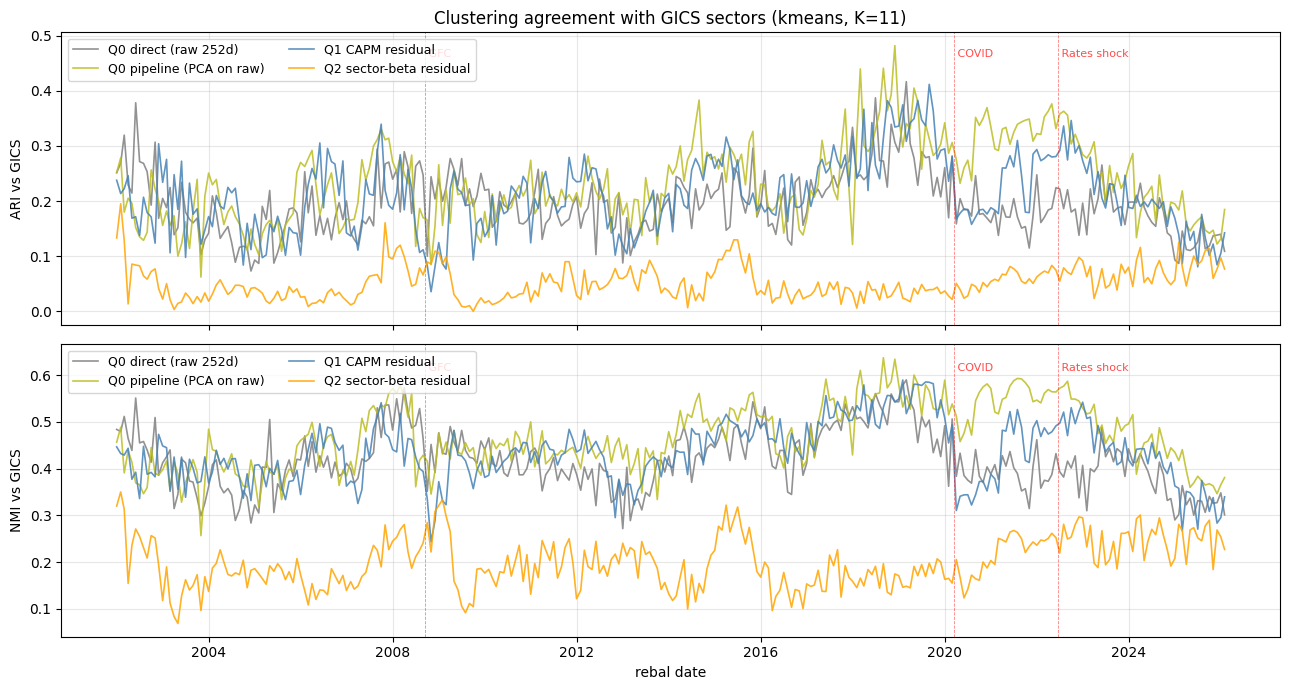

In [14]:
HEADLINE = [
    ("Q0_direct",   "K11", "kmeans", "tab:gray",   "Q0 direct (raw 252d)"),
    ("Q0_pipeline", "K11", "kmeans", "tab:olive",  "Q0 pipeline (PCA on raw)"),
    ("Q1",          "K11", "kmeans", "steelblue",  "Q1 CAPM residual"),
    ("Q2",          "K11", "kmeans", "orange",     "Q2 sector-beta residual"),
]

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for panel, K_scheme, method, color, label in HEADLINE:
    sub = per_window[(per_window["panel"] == panel)
                      & (per_window["K_scheme"] == K_scheme)
                      & (per_window["method"] == method)].sort_values("rebal_date")
    axes[0].plot(sub["rebal_date"], sub["ARI"], color=color, lw=1.2, label=label, alpha=0.85)
    axes[1].plot(sub["rebal_date"], sub["NMI"], color=color, lw=1.2, label=label, alpha=0.85)

for ax, ylab in zip(axes, ["ARI vs GICS", "NMI vs GICS"]):
    ax.set_ylabel(ylab); ax.grid(alpha=0.3)
    ax.legend(loc="upper left", ncol=2, fontsize=9)
    for x, lab in [("2008-09-15", "GFC"), ("2020-03-15", "COVID"),
                    ("2022-06-15", "Rates shock")]:
        ax.axvline(pd.Timestamp(x), color="red", lw=0.6, alpha=0.5, ls="--")
        ax.text(pd.Timestamp(x), ax.get_ylim()[1] * 0.94, " " + lab,
                color="red", fontsize=8, alpha=0.7, va="top")
axes[0].set_title("Clustering agreement with GICS sectors (kmeans, K=11)")
axes[1].set_xlabel("rebal date")
fig.tight_layout()
fig.savefig("outputs/ari_nmi_timeseries.png", dpi=130)
plt.show()


## 7. Persist results

`outputs/ari_nmi_summary.csv` is the headline table I'll cite in the writeup. `outputs/ari_nmi_per_window.csv` is the full long-form data for any follow-on analysis.


In [15]:
summary.to_csv("outputs/ari_nmi_summary.csv", index=False)
per_window.to_csv("outputs/ari_nmi_per_window.csv", index=False)
print("Wrote outputs/ari_nmi_summary.csv and outputs/ari_nmi_per_window.csv")
print("Wrote outputs/ari_nmi_timeseries.png")


Wrote outputs/ari_nmi_summary.csv and outputs/ari_nmi_per_window.csv
Wrote outputs/ari_nmi_timeseries.png
